# Image Preprocessing with OpenCV

A short Python experiment in reducing noise and adjusting contrast using OpenCV.

**Input:** `assets/noisy_image_sample.png` is a newly generated synthetic image (not the original photograph in the private notebook). Different images may respond differently to filtering.

## 1. Load the image and define a display helper

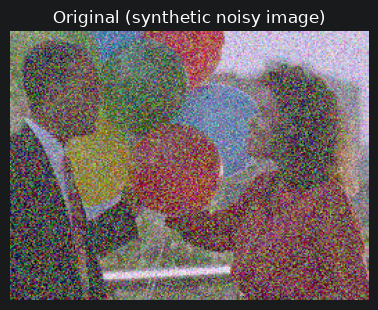

In [3]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

image_path = Path("assets/noisy_image_sample.png")
image = cv2.imread(str(image_path))
if image is None:
    raise FileNotFoundError(f"Could not read input image: {image_path}")

def show_images(images, columns=3):
    """Display a labelled sequence of BGR/gray OpenCV arrays in Jupyter/Colab."""
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(12, rows * 3.2))
    axes = axes.ravel() if hasattr(axes, "ravel") else [axes]
    for ax, (title, frame) in zip(axes, images):
        if frame.ndim == 2:
            ax.imshow(frame, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    for ax in axes[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_images([("Original (synthetic noisy image)", image)], columns=1)

## 2. Colour denoising

Median filtering reduces impulse-like noise; bilateral filtering can smooth while keeping some edges. Applying the bilateral filter *after* the median filter creates a cumulative pipeline.

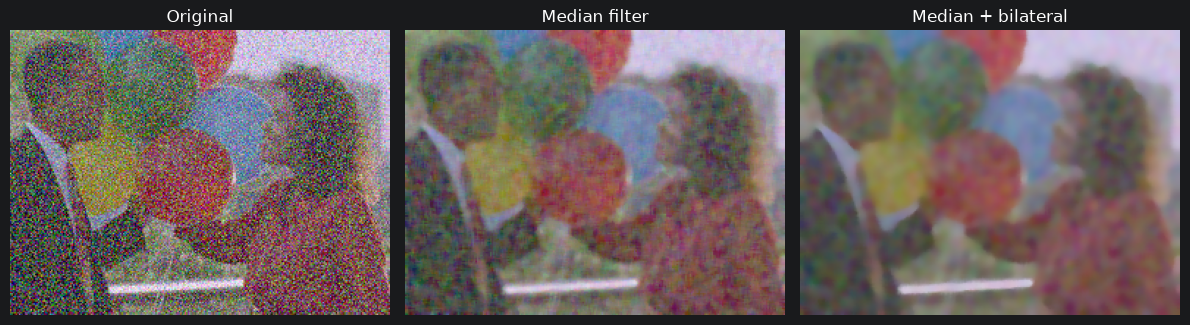

In [4]:
median_color = cv2.medianBlur(image, 5)
bilateral_color = cv2.bilateralFilter(median_color, 9, 75, 75)
show_images([
    ("Original", image),
    ("Median filter", median_color),
    ("Median + bilateral", bilateral_color),
])

## 3. Grayscale smoothing and contrast

The grayscale pipeline begins again from the original noisy image; it is **separate** from the colour pipeline. Histogram equalization and CLAHE may boost noise as well as contrast.

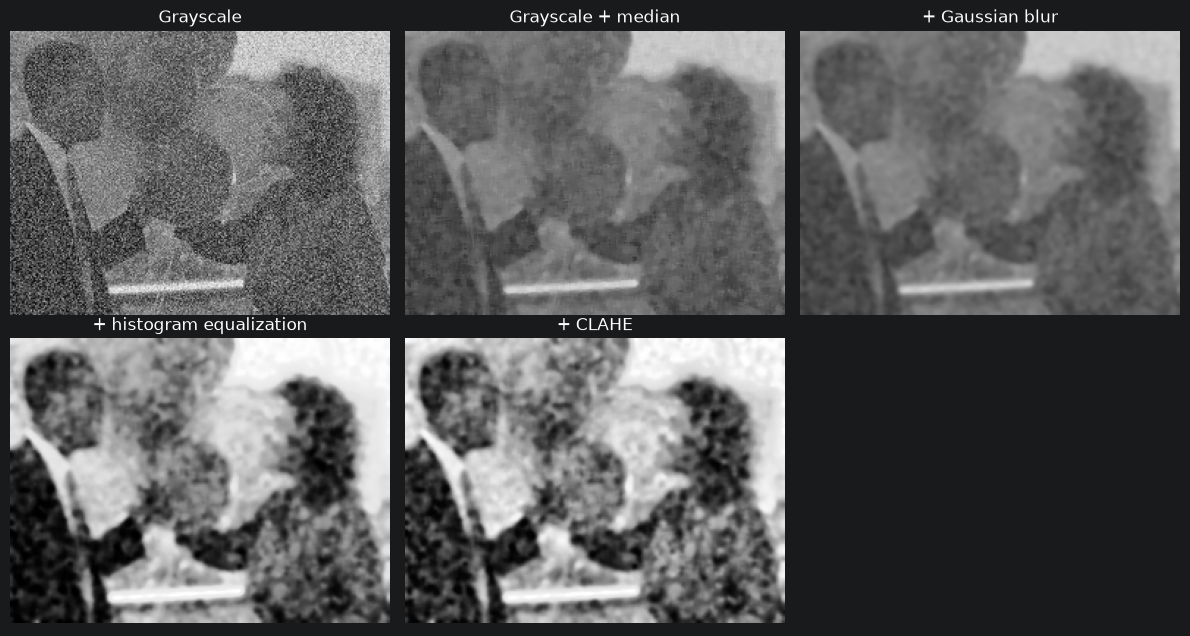

In [5]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
median_gray = cv2.medianBlur(gray, 5)
gaussian_gray = cv2.GaussianBlur(median_gray, (5, 5), 0)
hist_eq = cv2.equalizeHist(gaussian_gray)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_result = clahe.apply(hist_eq)

show_images([
    ("Grayscale", gray),
    ("Grayscale + median", median_gray),
    ("+ Gaussian blur", gaussian_gray),
    ("+ histogram equalization", hist_eq),
    ("+ CLAHE", clahe_result),
])

## 4. Save a result and summarize

These are visual comparisons, **not** measurements of OCR accuracy or objective image quality. Choose a filter based on the actual downstream task.

In [6]:
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)
saved_path = output_dir / "contrast_enhanced.png"
if not cv2.imwrite(str(saved_path), clahe_result):
    raise OSError(f"Could not write {saved_path}")
print("Saved grayscale result:", saved_path)

Saved grayscale result: output\contrast_enhanced.png
